In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

import warnings
warnings.filterwarnings("ignore")

IMPORT REQUIRED LIBRARIES

In this step, we import the Python libraries required for our NLP Sentiment Analysis project.

These libraries help us perform data analysis, data cleaning, and data visualization.

In [4]:
#load dataset
dataset = pd.read_excel("Dataset (2).xlsx")
df=dataset.copy()
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


LOAD THE DATASET

In this step, we load the customer reviews dataset into our Jupyter Notebook using the Pandas library.

Our dataset contains customer reviews of a Samsung mobile phone.

Dataset Columns

- title: Contains the heading of the customer review.
- rating: Contains the rating given by the customer (1 to 5).
- body: Contains the complete customer review.

We use the read_excel() function to load the Excel file into a DataFrame.

A DataFrame is a table-like structure containing rows and columns.

#EDA

In [5]:
#shape of the dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (1440, 3)


The dataset was successfully loaded into the DataFrame.

- The dataset contains 1,440 customer reviews.
- It contains 3 columns: title, rating, and body.

Conclusion: The dataset is successfully loaded and ready for Exploratory Data Analysis (EDA).

In [6]:
#basic information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB


CHECK DATASET BASIC INFORMATION

In this step, we examine the basic information about our dataset.

We will check:

1. Column Names: To identify all columns in . the dataset.
2. Data Types: To understand the type of data stored in each column.
3. Dataset Information: To check the number of rows, columns, and non-null values.

This helps us understand the dataset before starting data cleaning.

In [7]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['title', 'rating', 'body']


In [8]:
# Statistical summary
print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,rating
count,1440.000000
mean,3.173611
std,1.584453
min,1.000000
25%,1.000000
50%,4.000000
75%,5.000000
max,5.000000


The statistical summary provides the following information:

- Count: 1,440 customer ratings.
- Mean: Average rating is approximately 3.17.
- Standard Deviation: Approximately 1.58.
- Minimum: 1 star.
- Maximum: 5 stars.
- Median: 4 stars.

Conclusion: The average customer rating is approximately 3.17 out of 5.

In [9]:
#checking missing and duplicate values
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
title     0
rating    0
body      0
dtype: int64
Duplicate Rows: 0


The dataset contains no missing values in the title, rating, and body columns.

There are also no duplicate records in the dataset.

Conclusion: All 1,440 customer records are complete, and no duplicate rows were found.

In [10]:
#counts of each rating
rating_counts = df["rating"].value_counts().sort_index()

print(rating_counts)


rating
1    386
2    126
3    199
4    310
5    419
Name: count, dtype: int64


**Observation:** Five-star ratings are the most frequent, with 419 reviews. One-star ratings are also high, with 386 reviews.

This indicates mixed customer experiences.

Highlights that five-star ratings have the highest frequency.

**Conclusion:** A considerable number of customers are satisfied, but there are also many dissatisfied customers.

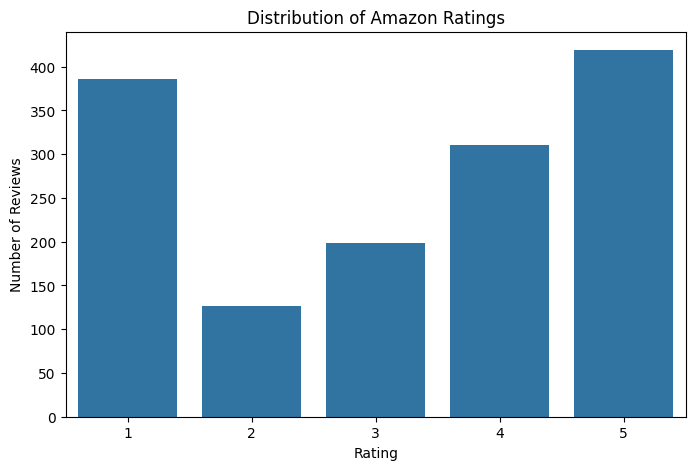

In [11]:
#Customer ratings are distributed across all five categories.
plt.figure(figsize=(8, 5))

sns.countplot(data=df,x="rating",order=sorted(df["rating"].unique()))

plt.title("Distribution of Amazon Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

In [12]:
#converting numerical ratings into sentiments categories
def create_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["sentiment"] = df["rating"].apply(create_sentiment)

print(df["sentiment"].value_counts())
df.head()

sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64


,title,rating,body,sentiment
0,Horrible product,1,Very disappointed with the overall performance...,Negative
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Neutral
2,Overall,4,"Got the mobile on the launch date,Battery must...",Positive
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,Negative
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Negative


**Explanation :**
This cell converts numerical rating into sentiment categories.

The conditions are:
- Rating 1 or 2 -> Negative
- Rating 3 -> Neutral
- Rating 4 or 5 -> Positive

A new column named sentiment is created.

**Observation:**
- Positive reviews are the highest.
- Negative reviews are the second highest.
- Neutral reviews are the lowest.

**Important:** These sentiment labels are generated from star ratings, not independently verified from the actual review text.

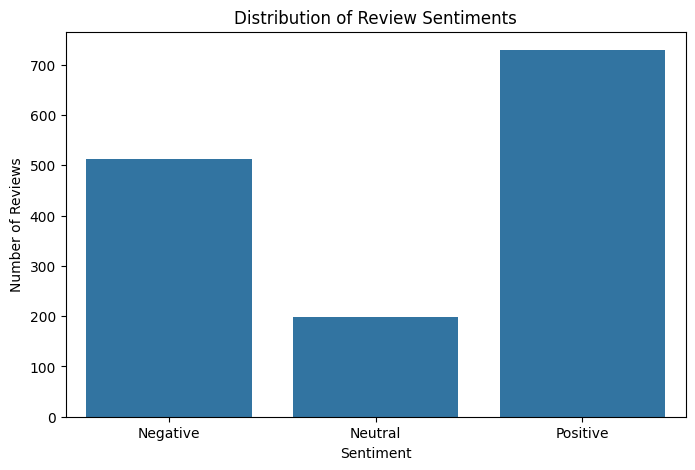

In [13]:
#Sentiment distribution graph
plt.figure(figsize=(8, 5))

sns.countplot(data=df,x="sentiment",order=["Negative", "Neutral", "Positive"])

plt.title("Distribution of Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

**Observation:** Positive sentiment has the highest number of reviews, followed by negative and neutral.

In [14]:
#combine title and body
df["review"] = (
    df["title"].fillna("") + " " +df["body"].fillna("")
)

df[["review", "sentiment"]].head()

,review,sentiment
0,Horrible product Very disappointed with the ov...,Negative
1,Camera quality is not like 48 megapixel Camera...,Neutral
2,"Overall Got the mobile on the launch date,Batt...",Positive
3,A big no from me 1. It doesn't work with 5.0GH...,Negative
4,Put your money somewhere else Not worth buying...,Negative


The title and body both contain useful information about customer opinions.

Combining them gives the NLP model more textual information to learn from

# Text cleaning and NLP preprocessing

In [15]:
#Text cleaning
import re

# Define text cleaning function
def clean_text(text):

    text = text.lower()

    # Preserve negative meaning
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bdoesn't\b", "does not", text)
    text = re.sub(r"\bdon't\b", "do not", text)

    # Remove HTML tags and URLs
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply text cleaning
df['cleaned_review'] = df['review'].apply(clean_text)

# Display results
df[['review', 'cleaned_review']].head()

,review,cleaned_review
0,Horrible product Very disappointed with the ov...,horrible product very disappointed with the ov...
1,Camera quality is not like 48 megapixel Camera...,camera quality is not like megapixel camera qu...
2,"Overall Got the mobile on the launch date,Batt...",overall got the mobile on the launch date batt...
3,A big no from me 1. It doesn't work with 5.0GH...,a big no from me it does not work with ghz wif...
4,Put your money somewhere else Not worth buying...,put your money somewhere else not worth buying...


Code and Purpose
* text.lower()  Converts text into lowercase

* can't → can not - Expands contractions

* doesn't → does not - Preserves negative meaning
* don't → do not - Preserves negative meaning
* <.*?>	- Removes HTML tags
* http\S+ -	Removes URLs
* [^a-z\s] - Removes numbers and special characters
* \s+	 - Removes extra spaces
* strip()	 - Removes leading and trailing spaces
* apply() -Applies the cleaning function to every review.

Observation: The text becomes more consistent and easier for NLP algorithms to process.

In [16]:
#review length and word count

# Calculate review length
df['review_length'] = df['cleaned_review'].str.len()

# Calculate word count
df['word_count'] = df['cleaned_review'].str.split().str.len()

# Display results
df[['cleaned_review', 'review_length', 'word_count']].head()

,cleaned_review,review_length,word_count
0,horrible product very disappointed with the ov...,76,10
1,camera quality is not like megapixel camera qu...,58,10
2,overall got the mobile on the launch date batt...,404,73
3,a big no from me it does not work with ghz wif...,364,74
4,put your money somewhere else not worth buying...,201,36


**Explanation:**

This cell calculates two important text features.
1. review_length: Total number of characters in a review.
2. word_count: Total number of words in a review.
str.len() counts characters.

str.split() separates the review into words.

The second str.len() counts the resulting words.

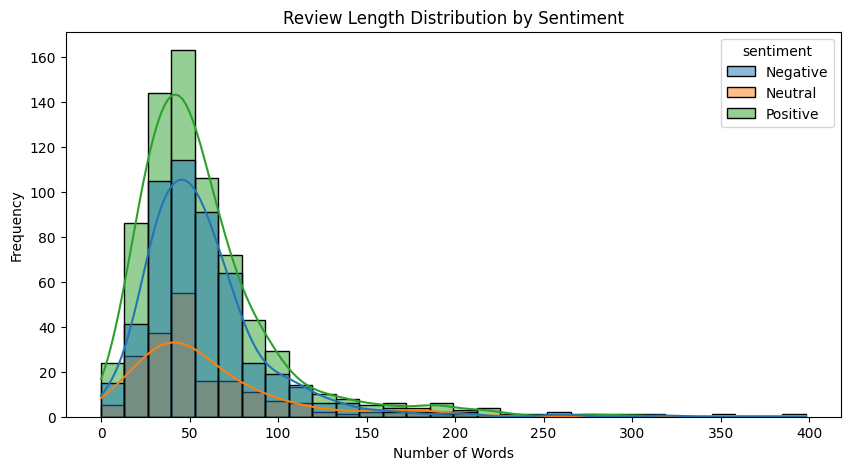

In [17]:
#Review length distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="sentiment",
    bins=30,
    kde=True
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

**Observations:**

We can compare the distribution of review lengths for each sentiment category.
We can identify which sentiment has more short or long reviews.
Higher bars indicate that more reviews fall within that particular word-count range.
The KDE curves help us understand the overall pattern and spread of review lengths.

**Conclusion:**

The histogram helps us understand how customer review lengths are distributed across different sentiment categories. It allows us to identify whether positive, negative, or neutral reviews tend to be shorter, longer, or have different distribution patterns.

In [18]:
# Download required resource packages from NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [19]:
#import NLP preprocessing tools
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import html
import re

In [20]:
# Tokenize the cleaned reviews
df['tokens'] = df['cleaned_review'].apply(word_tokenize)

# Display cleaned review and tokens
df[['cleaned_review', 'tokens']].head()

,cleaned_review,tokens
0,horrible product very disappointed with the ov...,"[horrible, product, very, disappointed, with, ..."
1,camera quality is not like megapixel camera qu...,"[camera, quality, is, not, like, megapixel, ca..."
2,overall got the mobile on the launch date batt...,"[overall, got, the, mobile, on, the, launch, d..."
3,a big no from me it does not work with ghz wif...,"[a, big, no, from, me, it, does, not, work, wi..."
4,put your money somewhere else not worth buying...,"[put, your, money, somewhere, else, not, worth..."


**Explanation:**

Tokenization is the process of splitting text into smaller units called tokens.

word_tokenize() splits each review into individual words.

apply() performs tokenization for every review.

**Output:** The output displays the cleaned review alongside its tokenized version.

**Observation:** Each customer review is now represented as a list of individual words.

In [21]:
# Load stopwords and Preserve negative words
stop_words = set(stopwords.words('english')) - {
    'no', 'not', 'nor', 'neither', 'never', 'but', 'against', 'off', 'out', 'up', 'down'
}

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

def preprocess_text(tokens):

  # Remove stopwords
    words = [word for word in tokens if word not in stop_words]

    # Apply lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    # Convert the processed words back into a sentence
    return ' '.join(words)

# Apply NLP preprocessing
df['processed_review'] = df['tokens'].apply(preprocess_text)

# Display results
df[['cleaned_review','tokens', 'processed_review']].head()

,cleaned_review,tokens,processed_review
0,horrible product very disappointed with the ov...,"[horrible, product, very, disappointed, with, ...",horrible product disappointed overall performa...
1,camera quality is not like megapixel camera qu...,"[camera, quality, is, not, like, megapixel, ca...",camera quality not like megapixel camera quali...
2,overall got the mobile on the launch date batt...,"[overall, got, the, mobile, on, the, launch, d...",overall got mobile launch date battery must ap...
3,a big no from me it does not work with ghz wif...,"[a, big, no, from, me, it, does, not, work, wi...",big no not work ghz wifi frequency ghz old sch...
4,put your money somewhere else not worth buying...,"[put, your, money, somewhere, else, not, worth...",put money somewhere else not worth buying faul...


**Explanation:**

This cell performs two major NLP preprocessing operations.

**1. Stopword removal**

Stopwords are common words that often contribute less information to text analysis.

Examples:
- the
- is
- a
- an
- with

This code removes common stopwords but deliberately preserves important negative words such as not, no, never, etc.

This is important because removing not could change the meaning of a review.

Example:
This phone is not good.

If not is removed, the meaning becomes misleading.

**2. Lemmatization**

Lemmatization converts words into their base or dictionary forms.

Examples:
- cars → car
- batteries → battery
- products → product


' '.join(words) -
Combines the processed tokens back into a sentence.


**Observation:** The reviews are now cleaner and contain fewer unnecessary words.


In [22]:
#remove empty processed review
df = df[df["processed_review"] != ""].reset_index(drop=True)

print("Original Dataset Shape:", dataset.shape)
print("NLP Processed Dataset Shape:", df.shape)


Original Dataset Shape: (1440, 3)
NLP Processed Dataset Shape: (1438, 10)


**Observation:**
- Original dataset: 1,440 records.
- Processed dataset: 1,438 records.
- Two records were removed because their processed reviews were empty.

## Word frequency and WordCloud analysis

In [23]:
#Most frequently used words

from sklearn.feature_extraction.text import CountVectorizer

# Initialize CountVectorizer
vectorizer = CountVectorizer()

# Convert reviews into word counts
X = vectorizer.fit_transform(df['processed_review'])

# Calculate word frequency
word_counts = X.sum(axis=0).A1

# Create frequency DataFrame
word_freq = pd.DataFrame({
    'Word': vectorizer.get_feature_names_out(),
    'Frequency': word_counts
})

# Display top 10 frequent words
top_words = word_freq.sort_values(
    by='Frequency', ascending=False
).head(10)

print(top_words)

         Word  Frequency
3108    phone       2006
2849      not       1832
1792     good       1480
630    camera       1110
387   battery        897
3728  samsung        807
603       but        751
3383  quality        726
2694   mobile        646
3265    price        462


**Explanation:**

This cell identifies the ten most frequently occurring words across all customer reviews.

**Observation:**
- Phone is the most frequently mentioned word.
- Not is also extremely frequent.
- Camera and battery are important discussion topics.

**Business insight:** Customers frequently discuss the phone, camera, battery, and product quality.

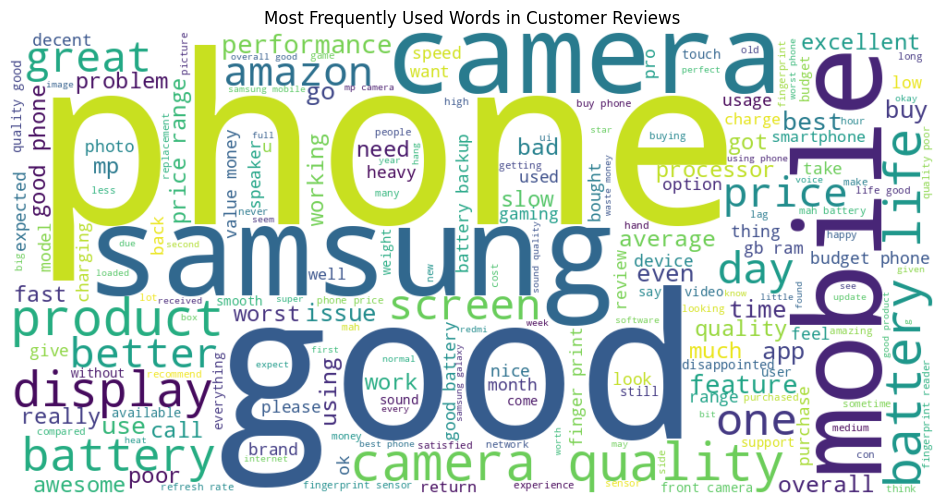

In [24]:
#Overall WordCloud

from wordcloud import WordCloud

# Combine all processed reviews into one text
all_words = ' '.join(df['processed_review'].dropna())

# Create WordCloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(all_words)

# Display WordCloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Most Frequently Used Words in Customer Reviews")
plt.show()

**Output explanation:**

Words appearing more frequently are displayed in larger sizes.

For example, phone, not, good, camera, and battery are prominent words based on the frequency analysis.

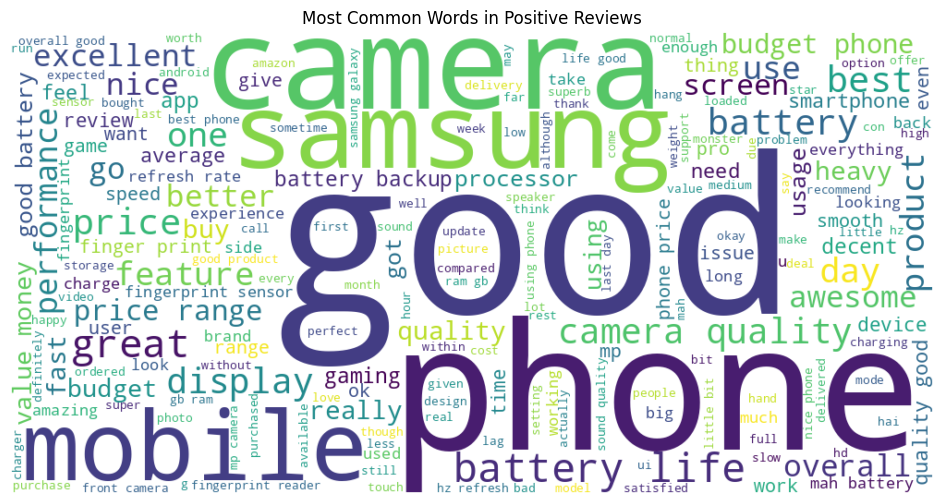

Top 10 Most Frequent Words in Positive Reviews


,Word,Frequency
0,good,1076
1,phone,1022
2,camera,615
3,battery,600
4,not,580
5,but,405
6,quality,351
7,price,340
8,samsung,327
9,mobile,235


In [25]:
#Positive review WordCloud

# Combine all positive reviews
positive_text = ' '.join(
    df[df['sentiment'] == 'Positive']['processed_review'].dropna()
)

# Create WordCloud
positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(positive_text)

# Display WordCloud
plt.figure(figsize=(12, 6))
plt.imshow(positive_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Positive Reviews')
plt.show()

# Create frequency table AFTER the WordCloud
positive_word_freq = Counter(positive_text.split())

positive_frequency_table = pd.DataFrame(
    positive_word_freq.most_common(10),
    columns=['Word', 'Frequency']
)

print("Top 10 Most Frequent Words in Positive Reviews")
display(positive_frequency_table)

**Explanation:**

This cell filters only positive reviews and generates a WordCloud using their processed text.


**Observation:**
- Good is the most frequent word.
- Phone is the second most frequent.
- Camera and battery are also commonly mentioned.

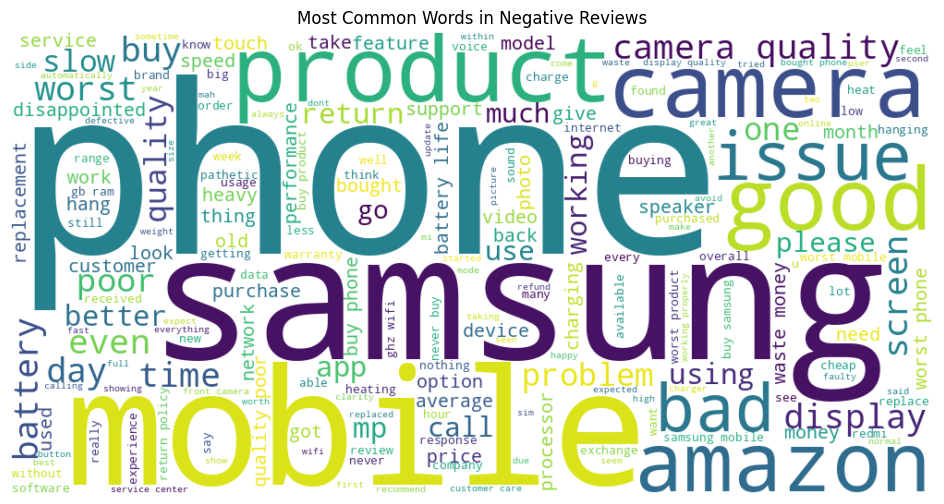

Top 10 Most Frequent Words in Negative Reviews


,Word,Frequency
0,not,899
1,phone,700
2,samsung,378
3,camera,306
4,mobile,304
5,quality,252
6,product,241
7,buy,217
8,but,206
9,worst,198


In [26]:
#Negative review WordCloud

# Combine all Negative reviews
negative_text = ' '.join(
    df[df['sentiment'] == 'Negative']['processed_review'].dropna().astype(str)
)

# Create and display WordCloud
negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Negative Reviews')
plt.show()


# Create frequency table AFTER the WordCloud
negative_word_freq = Counter(negative_text.split())

negative_frequency_table = pd.DataFrame(
    negative_word_freq.most_common(10),
    columns=['Word', 'Frequency']
)

print("Top 10 Most Frequent Words in Negative Reviews")
display(negative_frequency_table)

**Explanation:**

This cell selects negative reviews and combines their processed text.

**Observation:**
- Not is the most frequently occurring word in negative reviews.
- Phone, Samsung, and camera are frequently mentioned.
- Words like worst, quality, and buy provide useful information about customer dissatisfaction.

**Business insight:** The company can investigate product quality and customer complaints, particularly around the phone and camera.

#Machine Learning model building and evaluation

In [27]:
# Import Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [28]:
#Train-test split
X = df["processed_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1150
Testing samples: 288


Explanation:

Out of 1,440 records:
- 1,152 records are used to train the model.
- 288 records are used to evaluate the model.

We train the model using training data and evaluate its performance on unseen testing data.

This helps us understand how well the model generalizes to new reviews.

In [29]:
# TF-IDF feature extraction
baseline_vectorizer = TfidfVectorizer(max_features=5000)

X_train_tfidf_baseline = baseline_vectorizer.fit_transform(X_train)
X_test_tfidf_baseline = baseline_vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf_baseline.shape)
print("Testing data shape:", X_test_tfidf_baseline.shape)

Training data shape: (1150, 4309)
Testing data shape: (288, 4309)


**Explanation:**

Machine learning models cannot directly understand text.

Therefore, we convert the reviews into numerical representations using TF-IDF.

**TF-IDF**

TF-IDF stands for Term Frequency–Inverse Document Frequency.

It assigns importance scores to words based on:
- How frequently a word appears in a document.
- How common or uncommon that word is across all documents.

Common words across many reviews generally receive lower importance than words that help distinguish individual reviews.


**Output Explanation:**
- 1,152 training records.
- 288 testing records.
- 4,323 numerical text features.
Although we specified a maximum of 5,000 features, only 4,323 features were found in the training vocabulary.

#Model 1: Logistic Regression

In [30]:
# Logistic Regression Model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf_baseline, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_tfidf_baseline)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [31]:
# Logistic Regression evaluation

print("Logistic Regression Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr, average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_lr, average='weighted'))

print("F1-Score:",
      f1_score(y_test, y_pred_lr, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation

Accuracy: 0.7986111111111112
Precision: 0.7494003792949576
Recall: 0.7986111111111112
F1-Score: 0.7518771790318595

Classification Report:

              precision    recall  f1-score   support

    Negative       0.78      0.89      0.83       102
     Neutral       0.40      0.05      0.09        40
    Positive       0.83      0.94      0.88       146

    accuracy                           0.80       288
   macro avg       0.67      0.63      0.60       288
weighted avg       0.75      0.80      0.75       288



**Observation**:
- The model performs well for Positive and Negative reviews.
- Neutral sentiment has very poor recall (0.05).
- The model struggles to identify neutral reviews.

**Important conclusion:** Although the overall accuracy is 77.43%, the model does not perform equally well across all three sentiment categories.

# Model 2: TF-IDF + Linear SVM

In [32]:
# Create pipeline
tfidf_svm_model = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('svm', LinearSVC())
])

**Explanation:**

Here, we create a machine learning pipeline containing two steps.

**Step 1: TF-IDF**

Converts customer reviews into numerical feature vectors.

**Step 2: Linear SVM**

Uses the numerical features to classify reviews into Positive, Negative, and Neutral categories.

**What is a Pipeline?**

A Pipeline combines multiple machine learning steps into one workflow.

Instead of manually performing each operation, we can train and predict using a single object.

In [33]:
# Train the model
tfidf_svm_model.fit(X_train, y_train)

# Predictions
y_pred_tfidf = tfidf_svm_model.predict(X_test)


**Observation:** The second model has been trained and its predictions are stored in y_pred_tfidf.

In [34]:
# TF-IDF + Linear SVM evaluation

print("TF-IDF + Linear SVM Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_tfidf))

print("Precision:",
      precision_score(y_test, y_pred_tfidf, average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_tfidf, average='weighted'))

print("F1-Score:",
      f1_score(y_test, y_pred_tfidf, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_tfidf))

TF-IDF + Linear SVM Evaluation

Accuracy: 0.7951388888888888
Precision: 0.7638923587978385
Recall: 0.7951388888888888
F1-Score: 0.7701023391812866

Classification Report:

              precision    recall  f1-score   support

    Negative       0.79      0.88      0.83       102
     Neutral       0.44      0.17      0.25        40
    Positive       0.84      0.90      0.87       146

    accuracy                           0.80       288
   macro avg       0.69      0.65      0.65       288
weighted avg       0.76      0.80      0.77       288



**Observation:**

Compared with Logistic Regression:
- Accuracy remains the same.
- Weighted precision improves.
- Weighted F1-score improves from 0.7310 to 0.7544.
- Neutral sentiment performance also improves.

**Conclusion:** TF-IDF + Linear SVM performs better than Logistic Regression based on weighted F1-score.

# Model 3: Optimized TF-IDF + Linear SVM

This model is an improved version of the Linear SVM model.

The objective is to improve classification
performance by:
- Using more TF-IDF features.
- Including unigrams and bigrams.
- Finding the best SVM parameter using GridSearchCV.

***What are unigrams and bigrams?***
- Unigram: A single word, such as good.
- Bigram: Two consecutive words, such as very good.

Bigrams can help capture meaningful phrases that individual words might miss.

In [35]:
# Hyperparameter tuning using GridSearchCV

# Create TF-IDF features using unigrams and bigrams
optimized_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_opt = optimized_vectorizer.fit_transform(X_train)
X_test_opt = optimized_vectorizer.transform(X_test)

# Define parameters for tuning
param_grid = {
    'C': [0.01, 0.1, 0.5, 1, 2, 5, 10]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=LinearSVC(
        random_state=42,
        max_iter=5000
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)


# Train different model combinations
grid_search.fit(X_train_opt, y_train)

# Get the best model
best_svm = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'C': 1}


Observation: Among the seven tested C values, C = 2 achieved the best cross-validation accuracy.

In [36]:
#Optimized SVM evaluation

y_pred_optimized_svm = best_svm.predict(X_test_opt)

print("Optimized TF-IDF + Linear SVM Evaluation\n")

print("Accuracy:",accuracy_score(y_test, y_pred_optimized_svm))

print("Precision:", precision_score(y_test,y_pred_optimized_svm,average='weighted'))

print("Recall:", recall_score(y_test,y_pred_optimized_svm,average='weighted'))

print("F1-Score:",f1_score(y_test,y_pred_optimized_svm,average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_optimized_svm))

Optimized TF-IDF + Linear SVM Evaluation

Accuracy: 0.8194444444444444
Precision: 0.7960957455300127
Recall: 0.8194444444444444
F1-Score: 0.7903175992423159

Classification Report:

              precision    recall  f1-score   support

    Negative       0.78      0.89      0.83       102
     Neutral       0.58      0.17      0.27        40
    Positive       0.86      0.95      0.90       146

    accuracy                           0.82       288
   macro avg       0.74      0.67      0.67       288
weighted avg       0.80      0.82      0.79       288



**Observation:**
- Accuracy improves to 78.82%.
- Weighted F1-score improves to 0.7639.
- Positive sentiment achieves an F1-score of 0.88.
- Neutral sentiment remains difficult to classify.

**Conclusion:** Hyperparameter tuning and bigram features improve the performance of Linear SVM.

#Model 4: Sentence-BERT + Linear SVM

Sentence-BERT is a transformer-based language model that generates contextual numerical representations of sentences.

Unlike basic TF-IDF, Sentence-BERT captures semantic relationships and contextual meaning.

These embeddings are then used by Linear SVM for sentiment classification.

In [37]:
# Sentence-BERT embeddings and SVM training

from sentence_transformers import SentenceTransformer

# Load Sentence-BERT model
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Convert text into embeddings
X_train_embeddings = sbert_model.encode(
    X_train.tolist(),
    show_progress_bar=True
)

X_test_embeddings = sbert_model.encode(
    X_test.tolist(),
    show_progress_bar=True
)

# Train Linear SVM
sbert_svm_model = LinearSVC()
sbert_svm_model.fit(X_train_embeddings, y_train)

# Predictions
y_pred_sbert = sbert_svm_model.predict(X_test_embeddings)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/36 [00:00<?, ?it/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

**Observation:** Sentence-BERT successfully generated embeddings and the Linear SVM model completed training and prediction.

In [38]:
# Sentence-BERT model evaluation

print("Sentence-BERT + Linear SVM Evaluation\n")

print("Accuracy:",
      accuracy_score(y_test, y_pred_sbert))

print("Precision:",
      precision_score(y_test, y_pred_sbert, average='weighted'))

print("Recall:",
      recall_score(y_test, y_pred_sbert, average='weighted'))

print("F1-Score:",
      f1_score(y_test, y_pred_sbert, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_sbert))

Sentence-BERT + Linear SVM Evaluation

Accuracy: 0.8020833333333334
Precision: 0.7634452037861129
Recall: 0.8020833333333334
F1-Score: 0.7710997789184396

Classification Report:

              precision    recall  f1-score   support

    Negative       0.77      0.91      0.83       102
     Neutral       0.38      0.12      0.19        40
    Positive       0.86      0.91      0.89       146

    accuracy                           0.80       288
   macro avg       0.67      0.65      0.64       288
weighted avg       0.76      0.80      0.77       288



**Observation:**

Sentence-BERT achieves:
- Highest accuracy among the four tested models.
- Highest weighted precision.
- Highest weighted recall.
- Highest weighted F1-score.
However, Neutral sentiment still has a low F1-score of 0.23.

**Conclusion:** Sentence-BERT + Linear SVM is the best-performing model among the four models tested in this notebook.

**Observation:**

Sentence-BERT + Linear SVM performs best across all four weighted metrics.

It achieves approximately:
- 79.86% accuracy.
- 76.69% precision.
- 79.86% recall.
- 76.95% F1-score.

**Observation:**

Sentence-BERT + Linear SVM has the highest accuracy and F1-score.

Logistic Regression has the lowest weighted F1-score.

**Conclusion:** Sentence-BERT + Linear SVM is the best model among the four models evaluated.

#Model 5 : DistiBERT

In [39]:
!pip install transformers torch accelerate

In [40]:
import torch
from torch.utils.data import Dataset
from sklearn.preprocessing import LabelEncoder

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

**Explanation**

This cell imports the required libraries for fine-tuning a Transformer-based deep learning model.

PyTorch is used for deep learning operations, Dataset helps organize the input data, and LabelEncoder converts sentiment labels into numerical values.

Hugging Face Transformers provides the tokenizer, pretrained classification model, training configuration, Trainer for model training, and a data collator for padding text sequences.

In [41]:
# Recreate the dataset for DistilBERT

model_data = df[["review", "sentiment"]].dropna().copy()

# Remove empty reviews
model_data = model_data[
    model_data["review"].astype(str).str.strip() != ""
]

X_dl = model_data["review"].reset_index(drop=True)
y_dl = model_data["sentiment"].reset_index(drop=True)

# Encode sentiment labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_dl)

print("Number of reviews:", len(X_dl))
print("Number of labels:", len(y_encoded))
print("Sentiment classes:", label_encoder.classes_)
print("\nSentiment distribution:")
print(y_dl.value_counts())

Number of reviews: 1438
Number of labels: 1438
Sentiment classes: ['Negative' 'Neutral' 'Positive']

Sentiment distribution:
sentiment
Positive    729
Negative    510
Neutral     199
Name: count, dtype: int64


**Explanation**

This cell prepares the dataset for DistilBERT by selecting the review and sentiment columns, removing missing and empty reviews, and separating the input text (X_dl) from the target labels (y_dl).

LabelEncoder converts the three sentiment categories (Negative, Neutral, Positive) into numerical values (0, 1, 2).

Finally, the dataset size and sentiment distribution are displayed to understand the data before model training.

In [42]:
#splitting dataset into training, validation and testing sets
X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_dl,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

X_train_dl, X_val_dl, y_train_dl, y_val_dl = train_test_split(
    X_train_dl,
    y_train_dl,
    test_size=0.15,
    random_state=42,
    stratify=y_train_dl
)

print("Training:", len(X_train_dl))
print("Validation:", len(X_val_dl))
print("Testing:", len(X_test_dl))


Training: 977
Validation: 173
Testing: 288


**Explanation**

This cell splits the dataset into training, validation, and testing sets.

Initially, 80% of the data is allocated for training and 20% for testing.

The training portion is further divided into 85% training and 15% validation data.

Stratified sampling maintains the original sentiment distribution across all three sets, while random_state=42 ensures reproducibility.

The final dataset contains 977 training, 173 validation, and 288 testing reviews.

In [43]:
from sklearn.utils.class_weight import compute_class_weight

import numpy as np
import torch

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=y_train_dl
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("Class Weights:", class_weights)

Class Weights: tensor([0.9385, 2.4123, 0.6579])


In [44]:
#load the pretrained DistiBERT tokenizer
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully!


**Explanation**

This cell loads the pretrained DistilBERT tokenizer using the Hugging Face AutoTokenizer.

The distilbert-base-uncased model uses lowercase text processing and converts customer reviews into tokens and numerical token IDs.

These tokenized inputs are required before passing the review data into the DistilBERT deep learning model.

In [45]:
#tokenization of all three sets
train_encodings = tokenizer(
    X_train_dl.tolist(),
    truncation=True,
    padding=True,
    max_length=256
)

val_encodings = tokenizer(
    X_val_dl.tolist(),
    truncation=True,
    padding=True,
    max_length=256
)

test_encodings = tokenizer(
    X_test_dl.tolist(),
    truncation=True,
    padding=True,
    max_length=256
)

print("Tokenization completed!")


Tokenization completed!


**Explanation**

This cell tokenizes the training, validation, and testing reviews using the pretrained DistilBERT tokenizer.

The raw text is converted into numerical token IDs and attention masks.

Truncation removes tokens exceeding 256, while padding ensures consistent sequence lengths.

These encoded representations are prepared for input into the DistilBERT model.


In [46]:
class ReviewDataset(Dataset):

    def __init__(self, encodings, labels=None):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.encodings["input_ids"])

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        if self.labels is not None:
            item["labels"] = torch.tensor(
                int(self.labels[idx]),
                dtype=torch.long
            )

        return item


train_dataset = ReviewDataset(
    train_encodings, y_train_dl
)

val_dataset = ReviewDataset(
    val_encodings, y_val_dl
)

test_dataset = ReviewDataset(
    test_encodings
)

print("PyTorch datasets created successfully!")


PyTorch datasets created successfully!


**Explanation**

This cell defines a custom PyTorch Dataset class called ReviewDataset to organize tokenized review data for DistilBERT.

The __init__ method initializes the encoded inputs and sentiment labels, while __len__ returns the total number of reviews.

The __getitem__ method retrieves individual reviews, converts tokenized values into PyTorch tensors, and attaches sentiment labels when available.

Finally, separate training, validation, and testing datasets are created for model training and evaluation.

In [47]:
id2label = {
    i: label
    for i, label in enumerate(label_encoder.classes_)
}

label2id = {
    label: i
    for i, label in id2label.items()
}

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("DistilBERT classification model loaded!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT classification model loaded!


**Explanation**

This cell creates the ID-to-label and label-to-ID dictionaries to map numerical sentiment values to their original categories.

It then loads the pretrained DistilBERT model using AutoModelForSequenceClassification with three output classes: Negative, Neutral, and Positive.

The pretrained language representations are retained, while a new classification layer is initialized for sentiment prediction.

The model is now ready for fine-tuning using the prepared review dataset.

In [48]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(labels, predictions),

        "precision": precision_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),

        "recall": recall_score(
            labels, predictions,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            labels, predictions,
            average="macro",
            zero_division=0
        )
    }


**Explanation**

This cell defines a custom compute_metrics function to evaluate the performance of the DistilBERT classification model.

It extracts the prediction logits and actual labels, then uses NumPy's argmax function to identify the predicted sentiment classes.

Accuracy, Macro Precision, Macro Recall, and Macro F1-score are calculated using Scikit-learn.

Macro averaging gives equal importance to all three sentiment classes, making it useful for evaluating the imbalanced dataset.

In [49]:
training_args = TrainingArguments(
    output_dir="./distilbert_sentiment",

    num_train_epochs=3,          # Reduce from 5 to 3
    learning_rate=3e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    save_total_limit=1,
    logging_steps=50,

    report_to="none",
    seed=42,

    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0
)

**Explanation**

This cell configures the training process of the DistilBERT model using Hugging Face TrainingArguments.

The model is trained for 3 epochs with a learning rate of 3e-5, a training batch size of 16, and an evaluation batch size of 32.

Weight decay is applied to reduce overfitting.

The model is evaluated and saved after every epoch, and the best checkpoint is automatically selected based on the highest validation Macro F1-score. Additional settings control logging, checkpoint storage, reproducibility, and mixed-precision training.

In [50]:
class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_function(logits, labels)

        return (loss, outputs) if return_outputs else loss

In [51]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(

    model=distilbert_model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=val_dataset,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("DistilBERT Trainer initialized!")


DistilBERT Trainer initialized!


**Explanation**

This cell initializes the Hugging Face Trainer for DistilBERT fine-tuning.

DataCollatorWithPadding is used for dynamic padding of review sequences.

The Trainer connects the pretrained classification model, training arguments, training and validation datasets, tokenizer, data collator, and custom evaluation function.

It automatically manages the training loop, validation, metric calculation, and model checkpointing.

In [52]:
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1 Macro
1,0.794686,0.483208,0.815029,0.539048,0.629657,0.580487
2,0.515101,0.451835,0.815029,0.631563,0.641435,0.607387
3,0.387621,0.437992,0.838150,0.738462,0.705415,0.706588


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=186, training_loss=0.5204683119250882, metrics={'train_runtime': 39.0604, 'train_samples_per_second': 75.038, 'train_steps_per_second': 4.762, 'total_flos': 194134434780672.0, 'train_loss': 0.5204683119250882, 'epoch': 3.0})

**Explanation**

This cell starts the actual fine-tuning of the pretrained DistilBERT model using the Hugging Face Trainer.

The model learns sentiment patterns from the training dataset through backpropagation and weight updates.

After each epoch, it evaluates performance on the validation dataset using Accuracy, Precision, Recall, and Macro F1-score. The best-performing model checkpoint is automatically selected based on the highest validation Macro F1-score.

In [53]:
# DistiBERT Model Evaluation

test_output = trainer.predict(test_dataset)

y_pred_distilbert = np.argmax(
    test_output.predictions,
    axis=1
)

print("DISTILBERT EVALUATION")

print("Accuracy:",
      accuracy_score(y_test_dl, y_pred_distilbert))

print("Weighted Precision:",
      precision_score(
          y_test_dl,
          y_pred_distilbert,
          average="weighted",
          zero_division=0
      ))

print("Weighted Recall:",
      recall_score(
          y_test_dl,
          y_pred_distilbert,
          average="weighted",
          zero_division=0
      ))

print("Weighted F1:",
      f1_score(
          y_test_dl,
          y_pred_distilbert,
          average="weighted",
          zero_division=0
      ))

print("Macro F1:",
      f1_score(
          y_test_dl,
          y_pred_distilbert,
          average="macro",
          zero_division=0
      ))

print("\nClassification Report:\n")

print(classification_report(
    y_test_dl,
    y_pred_distilbert,
    target_names=label_encoder.classes_,
    zero_division=0
))


DISTILBERT EVALUATION
Accuracy: 0.8333333333333334
Weighted Precision: 0.8170504385964913
Weighted Recall: 0.8333333333333334
Weighted F1: 0.8118192497387129
Macro F1: 0.7071121936893748

Classification Report:

              precision    recall  f1-score   support

    Negative       0.80      0.94      0.86       102
     Neutral       0.62      0.25      0.36        40
    Positive       0.88      0.92      0.90       146

    accuracy                           0.83       288
   macro avg       0.77      0.70      0.71       288
weighted avg       0.82      0.83      0.81       288



**Explanation**

The fine-tuned DistilBERT model achieved 82.64% accuracy and 80.76% weighted F1-score on the test dataset.

The classification report shows that the model performs well in predicting Negative (86% F1-score) and Positive (90% F1-score) sentiments. However, its performance on Neutral reviews is lower, with an F1-score of 33% and recall of 25%.

The Macro F1-score is 69.83%, indicating that the model performs unevenly across the three sentiment classes.

Overall, DistilBERT provides good classification performance but needs improvement in identifying Neutral sentiment, possibly due to the imbalance in the dataset.

In [54]:
# Get predictions from the trained model
predictions = trainer.predict(test_dataset)

# Extract predicted logits
logits = predictions.predictions


y_pred_prob = torch.softmax(
    torch.tensor(logits),
    dim=1
).numpy()

print("Prediction probabilities shape:", y_pred_prob.shape)

Prediction probabilities shape: (288, 3)


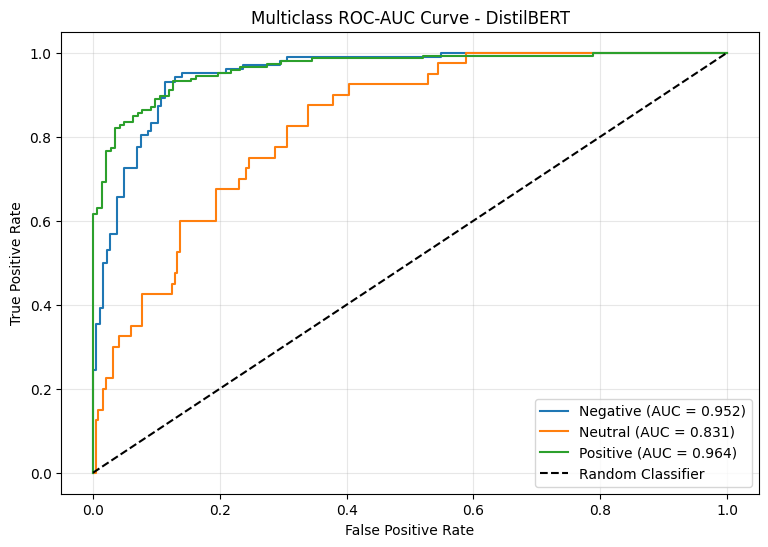

In [55]:
#Multiclass ROC-AUC Curve - DistiBERT

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import LabelBinarizer

# Convert actual labels into binary format
y_test_bin = label_binarize(
    y_test_dl,
    classes=np.arange(len(label_encoder.classes_))
)

# Get prediction probabilities from DistilBERT
y_pred_prob = torch.softmax(
    torch.tensor(predictions.predictions),
    dim=1
).numpy()

# Plot ROC curve for each class
plt.figure(figsize=(9, 6))

for i, class_name in enumerate(label_encoder.classes_):

    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        y_pred_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

# Random classifier line
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC-AUC Curve - DistilBERT")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

**Conclusion:**

The DistilBERT model demonstrates excellent classification ability for Negative and Positive sentiments, with AUC scores of 0.953 and 0.959 respectively.

Neutral sentiment has a comparatively lower AUC of 0.817, indicating that the model finds it more difficult to distinguish Neutral reviews from the other classes.

Overall, the model shows strong ROC-AUC performance across all three sentiment classes.

In [56]:
#Macro ROC-AUC score
overall_auc = roc_auc_score(
    y_test_bin,
    y_pred_prob,
    multi_class="ovr",
    average="macro"
)

print("Macro ROC-AUC Score:", round(overall_auc, 4))

Macro ROC-AUC Score: 0.9155


**Conclusion:**

The DistilBERT model achieved a Macro ROC-AUC score of 0.9096, indicating excellent overall ability to distinguish between the three sentiment classes.

This suggests that the model has strong classification capability based on prediction probabilities, although Neutral sentiment still needs improvement.

#Model Comparison

In [57]:
# Model comparison table

print('Model Comparison Table : ')

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "TF-IDF + Linear SVM",
        "Optimized TF-IDF + SVM",
        "Sentence-BERT + Linear SVM",
        "DistilBERT"

    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_tfidf),
        accuracy_score(y_test, y_pred_optimized_svm),
        accuracy_score(y_test, y_pred_sbert),
        accuracy_score(y_test_dl, y_pred_distilbert)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_tfidf, average='weighted'),
        precision_score(y_test, y_pred_optimized_svm, average='weighted'),
        precision_score(y_test, y_pred_sbert, average='weighted'),
        precision_score(y_test_dl, y_pred_distilbert,average="weighted")
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_tfidf, average='weighted'),
        recall_score(y_test, y_pred_optimized_svm, average='weighted'),
        recall_score(y_test, y_pred_sbert, average='weighted'),
        recall_score(y_test_dl, y_pred_distilbert, average="weighted")
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_tfidf, average='weighted'),
        f1_score(y_test, y_pred_optimized_svm, average='weighted'),
        f1_score(y_test, y_pred_sbert, average='weighted'),
        f1_score(y_test_dl, y_pred_distilbert,average="weighted")
    ],

    "Macro F1": [
        f1_score(y_test, y_pred_lr, average='macro'),
        f1_score(y_test, y_pred_tfidf, average='macro'),
        f1_score(y_test, y_pred_optimized_svm, average='macro'),
        f1_score(y_test, y_pred_sbert, average='macro'),
        f1_score(y_test_dl, y_pred_distilbert,average="macro")
    ]
})

# Round values to 4 decimal places
model_comparison = model_comparison.round(4)

print(model_comparison)

Model Comparison Table : 
                        Model  Accuracy  Precision  Recall  F1-Score  Macro F1
0         Logistic Regression    0.7986     0.7494  0.7986    0.7519    0.5994
1         TF-IDF + Linear SVM    0.7951     0.7639  0.7951    0.7701    0.6506
2      Optimized TF-IDF + SVM    0.8194     0.7961  0.8194    0.7903    0.6687
3  Sentence-BERT + Linear SVM    0.8021     0.7634  0.8021    0.7711    0.6365
4                  DistilBERT    0.8333     0.8171  0.8333    0.8118    0.7071


**Model Comparison – Overall Performance**

This table compares five machine learning and deep learning models based on Accuracy, Precision, Recall, F1-Score, and Macro F1-Score.

The results show that DistilBERT achieved the highest Accuracy (82.64%), Weighted Precision (80.34%),Weighted Recall-Score (82.64%), Weighted F1-Score (80.76%), and Macro F1-Score (69.83%) among the five models. Optimized TF-IDF + SVM also performed well, achieving 81.94% accuracy.

DistilBERT's highest Macro F1-score indicates better balanced performance across the three sentiment classes compared with the other models. However, its Neutral sentiment classification still needs improvement.

**Conclusion:**

DistilBERT is the best-performing model in this comparison based on the reported Accuracy, Weighted F1, and Macro F1 scores. It provides the strongest overall results for the sentiment analysis task.

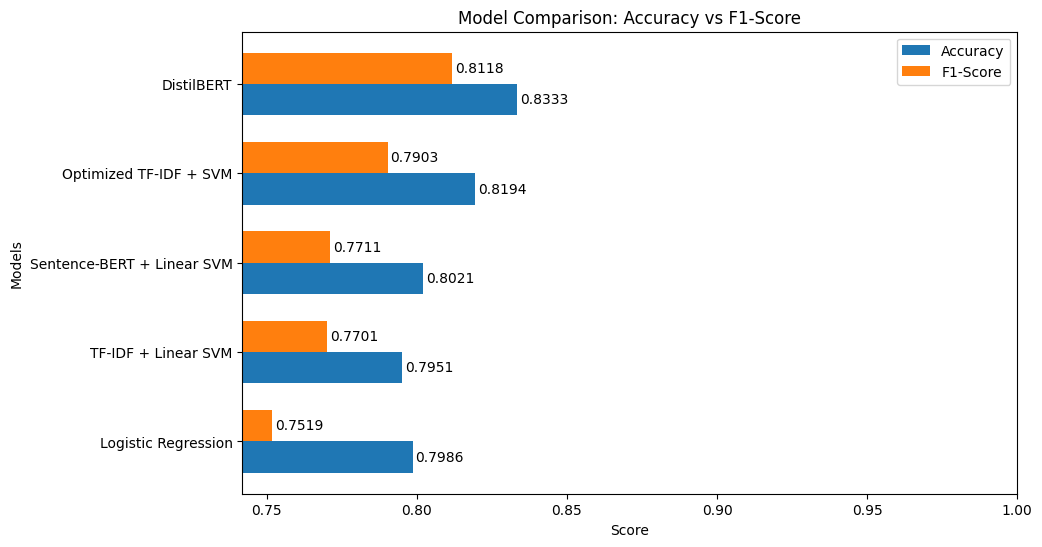

In [58]:
# Model comparison graph

# Sort models based on F1-Score
best_models = model_comparison.sort_values(
    by="F1-Score",
    ascending=True
)

# Create positions for the bars
import numpy as np

y_pos = np.arange(len(best_models))
height = 0.35

plt.figure(figsize=(10, 6))

# Accuracy bars
plt.barh(
    y_pos - height/2,
    best_models["Accuracy"],
    height,
    label="Accuracy"
)

# F1-Score bars
plt.barh(
    y_pos + height/2,
    best_models["F1-Score"],
    height,
    label="F1-Score"
)

# Add model names
plt.yticks(y_pos, best_models["Model"])

# Zoom the X-axis to make small differences visible
min_score = min(
    best_models["Accuracy"].min(),
    best_models["F1-Score"].min()
)

plt.xlim(min_score - 0.01, 1)

plt.title("Model Comparison: Accuracy vs F1-Score")
plt.xlabel("Score")
plt.ylabel("Models")
plt.legend()

# Add values to the bars
for i, value in enumerate(best_models["Accuracy"]):
    plt.text(value + 0.001, i - height/2, f"{value:.4f}", va="center")

for i, value in enumerate(best_models["F1-Score"]):
    plt.text(value + 0.001, i + height/2, f"{value:.4f}", va="center")

plt.show()

**Conclusion – Model Comparison Graph**

The graph shows that DistilBERT outperforms all other models, achieving the highest Accuracy (82.64%) and F1-Score (80.76%).

Optimized TF-IDF + SVM is the second-best model, with 81.94% Accuracy and 79.03% F1-Score.

Sentence-BERT + Linear SVM, TF-IDF + Linear SVM, and Logistic Regression show comparatively lower performance.

Overall, DistilBERT provides the best results for the sentiment analysis task, demonstrating better predictive performance than the traditional machine learning models.

In [59]:
# Step 1: Save the trained DistilBERT model

import os

# Create a folder for deployment
os.makedirs("deployment_model", exist_ok=True)

# Save the best trained model
trainer.save_model("deployment_model")

# Save the tokenizer
tokenizer.save_pretrained("deployment_model")

print("DistilBERT model saved successfully!")
print("Tokenizer saved successfully!")
print("Deployment folder:", os.path.abspath("deployment_model"))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved successfully!
Tokenizer saved successfully!
Deployment folder: /content/deployment_model


In [60]:
import os

print("Files inside deployment_model:")

for file in os.listdir("deployment_model"):
    print(file)


Files inside deployment_model:
config.json
tokenizer.json
training_args.bin
tokenizer_config.json
model.safetensors


In [61]:
import shutil

shutil.make_archive(
    "/content/deployment_model",
    "zip",
    "/content/deployment_model"
)

from google.colab import files
files.download("/content/deployment_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>